In [2]:
from pathlib import Path
from types import MappingProxyType
import math
import re
import warnings
from collections import Counter
from statistics import mean, stdev

import numpy as np
import pandas as pd

# EDIT THIS PATH ONLY if your project is stored somewhere else.
# Windows Python: the UNC path below. WSL/Linux Python: its native Linux path.
PROJECT_ROOT = Path(
    r"\\wsl.localhost\Ubuntu\home\samir\leveraging-constraints\final-project"
).expanduser()
if not PROJECT_ROOT.is_dir() and Path('/home/samir/leveraging-constraints/final-project').is_dir():
    PROJECT_ROOT = Path('/home/samir/leveraging-constraints/final-project')
PROJECT_ROOT = PROJECT_ROOT.resolve()
EXPERIMENTS = PROJECT_ROOT.parent / 'experiments'
OUTPUT_DIR = PROJECT_ROOT.parent / 'Reports' / 'Final Report' / 'tables_fixed'

# Immutable, distinct evaluation and training seed selections.
EVAL_SEEDS = tuple(range(1, 11)) + (42,)
FINETUNE_SEEDS = (1, 2, 42)
S4_TEST_SEED = 1
PROFILE_TRAIN_SEED = 42

FILE_SPECS = (
    ('EBI', 'EBI.jp2', 37422),
    ('MLK_excerpt_VBR_45-85', 'MLK_excerpt_VBR_45-85.mp3', 34163),
    ('View_huff3.cd', 'View_huff3.cd', 3218),
    ('watsoncrick', 'watsoncrick.pdf', 56910),
    ('wssnt10', 'wssnt10.txt', 21649),
)
MODELS = (
    ('5000_bacterial_benchmark_finetuned_45000', 'Whole-Model'),
    ('5000_images_model_decoder_finetune_45000', 'Decoder'),
) + tuple((f'5000_images_model_finetune_rank_{r}_45000', f'LoRA Rank {r}')
          for r in (1, 2, 4, 8, 16))
PARAMETER_COUNTS = MappingProxyType({
    'Whole-Model': 4833669, 'Decoder': 1285, 'LoRA Rank 1': 6144,
    'LoRA Rank 2': 12288, 'LoRA Rank 4': 24576,
    'LoRA Rank 8': 49152, 'LoRA Rank 16': 98304,
})
T1_ROOT = EXPERIMENTS / 'table61_eval_3train_10test'
S4_ROOT = EXPERIMENTS / 's4_combined'
PROFILE_ROOT = EXPERIMENTS / 'finetune_multiseed' / f'seed_{PROFILE_TRAIN_SEED}'

# Keys are internal names; displayed values use percentages.
CORE = ('Payload Accuracy', 'Alignment Success Rate', 'Median Read Accuracy')
RATES = ('Median Match Rate', 'Median Mismatch Rate', 'Median Insertion Rate', 'Median Deletion Rate')
FEATURE_KEYS = {
    'homopolymers': ('Mean Homopolymers Success', 'Mean Homopolymers Fail'),
    'length': ('Mean Length Success', 'Mean Length Fail'),
    'kl': ('Mean KL Success', 'Mean KL Fail'),
}
T1_FEATURES = ('homopolymers', 'length', 'kl')
T1_METRICS = tuple(k for f in T1_FEATURES for k in FEATURE_KEYS[f]) + CORE + RATES

BEAM_TABLES = (
    dict(number=4, folder='table71_repeats', features=('homopolymers',),
         configs=tuple((f'max_repeats_{h}_penalty_{p}', (p, str(h)))
                       for p,h in (('0.2',1),('0.2',2),('0.5',1),('0.5',2),('1',1)))),
    dict(number=5, folder='table73_74_repeats', features=('length',),
         configs=tuple((f'length_lambda_{v}', (str(v),)) for v in (1,5,10,15,20,25))),
    dict(number=6, folder='table73_74_repeats', features=('length',),
         configs=tuple((f'length_discard_{v}', (v,)) for v in ('0.05','0.1','0.2','0.5'))),
    dict(number=7, folder='table75_76_repeats', features=('kl',),
         configs=tuple((f'kl_penalty_{v}', (str(v),)) for v in (1,5,10,15,20))),
    dict(number=8, folder='table75_76_repeats', features=('kl',),
         configs=tuple((f'kl_discard_{v}', (v,)) for v in ('0.01','0.05','0.1'))),
    dict(number=9, folder='table77_repeats', features=(),
         configs=tuple((f'combined_no_repeats_length_lambda_{a}_kl_penalty_{b}', (str(a),str(b)))
                       for a in (5,10,15) for b in (1,5,10))),
)

# Optional explicit labels in profile.csv are used when available. The row
# indices are the schema used by the supplied notebook, not inferred timings.
PROFILE_ROW_INDICES = MappingProxyType({'Forward Pass': 2, 'Backward Pass': 0})

assert len(EVAL_SEEDS) == 11 and len(set(EVAL_SEEDS)) == 11
assert len(FINETUNE_SEEDS) == 3
print(f'Output directory: {OUTPUT_DIR}')


Output directory: \\wsl.localhost\Ubuntu\home\samir\leveraging-constraints\Reports\Final Report\tables_fixed


In [3]:
class TableDataError(ValueError):
    pass


def csv_checked(path, required_columns):
    if not path.is_file():
        raise FileNotFoundError(f'Required table input is missing: {path}')
    frame = pd.read_csv(path,dtype={'Query ID':str} if 'Query ID' in required_columns else None)
    missing = set(required_columns) - set(frame.columns)
    if missing:
        raise TableDataError(f'{path}: missing columns {sorted(missing)}')
    return frame


def fastq_records(path):
    """Streaming FASTQ reader supporting wrapped sequence/quality lines."""
    if not path.is_file():
        raise FileNotFoundError(f'Required sequence file is missing: {path}')
    with path.open(encoding='ascii') as handle:
        while True:
            header = handle.readline()
            if not header:
                return
            if not header.startswith('@'):
                raise TableDataError(f'{path}: malformed FASTQ header')
            pieces = []
            while True:
                line = handle.readline()
                if not line:
                    raise TableDataError(f'{path}: truncated FASTQ sequence')
                if line.startswith('+'):
                    break
                pieces.append(line.rstrip('\r\n'))
            sequence = ''.join(pieces).upper()
            quality_length = 0
            # An empty sequence still has a quality line.
            while quality_length < len(sequence) or (not sequence and quality_length == 0):
                line = handle.readline()
                if not line:
                    raise TableDataError(f'{path}: truncated FASTQ quality')
                quality_length += len(line.rstrip('\r\n'))
                if not sequence:
                    break
            if quality_length != len(sequence):
                raise TableDataError(f'{path}: sequence and quality lengths differ')
            yield header[1:].split()[0], sequence


def finite_weighted_average(values, weights):
    keep = [(float(v), float(w)) for v,w in zip(values,weights) if math.isfinite(float(v))]
    return math.fsum(v*w for v,w in keep)/math.fsum(w for _,w in keep) if keep else float('nan')


def sequence_features(path, aligned_ids, requested):
    keys = tuple(k for feature in requested for k in FEATURE_KEYS[feature])
    sums, counts = dict.fromkeys(keys, 0.0), {'Success':0, 'Fail':0}
    found_aligned = set()
    for query_id, sequence in fastq_records(path):
        group = 'Success' if query_id in aligned_ids else 'Fail'
        if group == 'Success':
            found_aligned.add(query_id)
        counts[group] += 1
        if 'homopolymers' in requested:
            sums[f'Mean Homopolymers {group}'] += len(re.findall(r'(.)\1{1,}',sequence))
        if 'length' in requested:
            sums[f'Mean Length {group}'] += len(sequence)
        if 'kl' in requested:
            if not sequence or set(sequence)-set('ACGT'):
                raise TableDataError(f'{path}: KL over A/C/G/T is undefined for empty/ambiguous read {query_id}')
            n = len(sequence)
            sums[f'Mean KL {group}'] += math.fsum((v/n)*math.log(4*v/n) for v in Counter(sequence).values())
    if found_aligned != aligned_ids:
        absent = sorted(aligned_ids-found_aligned)[:3]
        raise TableDataError(f'{path}: aligned query IDs absent from FASTQ, e.g. {absent}')
    return {k: sums[k]/counts[k.rsplit(' ',1)[1]] if counts[k.rsplit(' ',1)[1]] else float('nan') for k in keys}


def collect_run(path, features=()):
    """One run, retaining the original weighted file-average estimand.

    Failed-read features are calculated even when a file has zero alignments.
    Core metrics may not silently lose files or whole test seeds.
    """
    keys = tuple(k for f in features for k in FEATURE_KEYS[f]) + CORE + RATES
    per_file = {k:[] for k in keys}
    weights = []
    for directory,_,weight in FILE_SPECS:
        file_dir = path/directory
        aln = csv_checked(file_dir/'evaluation'/'alignment_stats.csv', ('Aligned Reads','Failed alignments'))
        if len(aln) != 1:
            raise TableDataError(f'{file_dir}: expected one alignment-summary row')
        row = aln.iloc[0]
        aligned, failed_aln = int(row['Aligned Reads']), int(row['Failed alignments'])
        bc = csv_checked(file_dir/'basecall_stats.csv', ('Read Succeeded',))
        failed_bc = int((bc['Read Succeeded']==0).sum())
        attempted = aligned+failed_aln+failed_bc
        if min(aligned,failed_aln,failed_bc)<0 or attempted<=0:
            raise TableDataError(f'{file_dir}: invalid alignment counts')
        # These fixed weights define the original estimator; validate them.
        if attempted != weight:
            raise TableDataError(f'{file_dir}: attempted count {attempted} differs from fixed sequence weight {weight}; check FILE_SPECS and count definitions')
        payload_path = file_dir/'payload_accuracy.txt'
        if not payload_path.is_file():
            raise FileNotFoundError(f'Required payload result is missing: {payload_path}')
        payload = float(payload_path.read_text().strip())
        if not math.isfinite(payload) or not 0<=payload<=1:
            raise TableDataError(f'{payload_path}: expected a finite fraction from 0 to 1')
        per_file['Payload Accuracy'].append(payload*100)
        per_file['Alignment Success Rate'].append(100*aligned/attempted)
        aligned_ids = set()
        if aligned:
            columns = ('Query ID','Accuracy','Match Rate','Mismatch Rate','Insertion Rate','Deletion Rate')
            ev = csv_checked(file_dir/'evaluation'/'evaluation.csv',columns)
            if ev.empty:
                raise TableDataError(f'{file_dir}: positive Aligned Reads but empty evaluation.csv')
            aligned_ids = set(ev['Query ID'].astype(str))
            for key,column in zip(('Median Read Accuracy',)+RATES,columns[1:]):
                numbers = pd.to_numeric(ev[column],errors='raise')
                if not np.isfinite(numbers).all() or not numbers.between(0,1).all():
                    raise TableDataError(f'{file_dir}: {column} must contain finite fractions from 0 to 1')
                per_file[key].append(float(numbers.median())*100)
        else:
            for key in ('Median Read Accuracy',)+RATES:
                per_file[key].append(float('nan'))
        if features:
            vals = sequence_features(file_dir/'basecalls.fastq',aligned_ids,features)
            for key,value in vals.items():
                per_file[key].append(value)
        weights.append(weight)
    merged = {key:finite_weighted_average(values,weights) for key,values in per_file.items()}
    if not all(math.isfinite(merged[key]) for key in CORE):
        raise TableDataError(f'{path}: a headline metric is undefined; cannot claim eleven complete paired observations. Do not substitute zero.')
    return merged


def describe(values):
    values = [float(x) for x in values]
    if not all(math.isfinite(x) for x in values):
        # Conditional sequence features alone can have truly empty groups.
        return float('nan'),float('nan')
    return mean(values),stdev(values) if len(values)>1 else 0.0


def check_inputs():
    required = []
    for s in EVAL_SEEDS:
        required.append(T1_ROOT/'baseline'/f'test_{s}'/'default')
        for training_seed in FINETUNE_SEEDS:
            required.extend(T1_ROOT/f'train_{training_seed}'/f'test_{s}'/model for model,_ in MODELS)
    seen = set()
    for spec in BEAM_TABLES:
        for s in EVAL_SEEDS:
            for setting in ('default',)+tuple(c[0] for c in spec['configs']):
                path = EXPERIMENTS/spec['folder']/f'seed_{s}'/setting
                if path not in seen:
                    required.append(path)
                    seen.add(path)
    for training_seed in FINETUNE_SEEDS:
        for model,_ in MODELS:
            required.extend(S4_ROOT/f'train_{training_seed}'/f'test_{S4_TEST_SEED}'/(model+suffix) for suffix in ('','_combined'))
    missing = [str(p) for p in required if not p.is_dir()]
    missing += [str(PROFILE_ROOT/model/'profile.csv') for model,_ in MODELS if not (PROFILE_ROOT/model/'profile.csv').is_file()]
    if missing:
        raise FileNotFoundError('Required table inputs are missing. Correct the configuration before running.\n'+'\n'.join(missing[:12])+(f'\n... {len(missing)} missing paths total' if len(missing)>12 else ''))


def load_all_table_results():
    check_inputs()
    t1 = {'baseline':{},'models':{label:{} for _,label in MODELS}}
    print('Reading Table 1 results...')
    for s in EVAL_SEEDS:
        t1['baseline'][s] = collect_run(T1_ROOT/'baseline'/f'test_{s}'/'default',T1_FEATURES)
    for model,label in MODELS:
        t1['models'][label] = {
            training_seed:{s:collect_run(T1_ROOT/f'train_{training_seed}'/f'test_{s}'/model,T1_FEATURES) for s in EVAL_SEEDS}
            for training_seed in FINETUNE_SEEDS
        }
    beam, cache = {},{}
    for spec in BEAM_TABLES:
        print(f"Reading Table {spec['number']} results...")
        values = {}
        for setting in ('default',)+tuple(c[0] for c in spec['configs']):
            values[setting] = {}
            for s in EVAL_SEEDS:
                path = EXPERIMENTS/spec['folder']/f'seed_{s}'/setting
                cache_key = (str(path),spec['features'])
                if cache_key not in cache:
                    cache[cache_key] = collect_run(path,spec['features'])
                values[setting][s] = cache[cache_key]
        beam[spec['number']] = values
    s4 = {}
    print('Reading S4 results...')
    for model,label in MODELS:
        s4[label] = {suffix:{s:collect_run(S4_ROOT/f'train_{s}'/f'test_{S4_TEST_SEED}'/(model+suffix))
                            for s in FINETUNE_SEEDS} for suffix in ('','_combined')}
    # Same datasets do not establish byte-identical independently saved baselines.
    different = []
    for number,table in beam.items():
        if any(not math.isclose(table['default'][s][m],t1['baseline'][s][m],rel_tol=0,abs_tol=1e-10)
               for s in EVAL_SEEDS for m in CORE):
            different.append(number)
    return {'t1':t1,'beam':beam,'s4':s4}


In [4]:
def latex_escape(text):
    return str(text).replace('\\',r'\textbackslash{}').replace('_',r'\_').replace('%',r'\%').replace('&',r'\&')


def number(value,digits=2):
    return 'NA' if not math.isfinite(float(value)) else f'{float(value):.{digits}f}'


def pm(values,digits=2,scale=1.0,show_sd=True):
    m,s = describe([float(v)*scale for v in values])
    if not math.isfinite(m):
        return 'NA'
    return number(m,digits)+(r' $\pm$ '+number(s,digits) if show_sd else '')


def latex_table(caption,label,headers,rows,note='',width=r'\linewidth',wide=False):
    n = len(headers[0])
    if any(len(h)!=n for h in headers) or any(isinstance(r,list) and len(r)!=n for r in rows):
        raise ValueError(f'LaTeX column-count mismatch in {label}')
    lines = [r'\begin{table}[!htb]']+([r'\begin{adjustwidth}{-2.25in}{0in}'] if wide else [])+[
             r'\centering',r'\caption{'+caption+'}',r'\label{'+label+'}',
             r'\resizebox{'+width+r'}{!}{%',r'\begin{tabular}{'+'l'+'c'*(n-1)+'}',r'\toprule']
    lines += [' & '.join(h)+r' \\' for h in headers]
    lines.append(r'\midrule')
    for row in rows:
        lines.append(row if isinstance(row,str) else ' & '.join(row)+r' \\')
    lines += [r'\bottomrule',r'\end{tabular}}']
    if note:
        lines.append(r'\begin{flushleft}\footnotesize '+note+r'\end{flushleft}')
    if wide:
        lines.append(r'\end{adjustwidth}')
    lines.append(r'\end{table}')
    return '\n'.join(lines)


AGGREGATION_NOTE = (
    r'File-specific summaries are weighted by encoded strand count. Read accuracy and M/X/I/D '
    r'are weighted means of file-specific medians, not pooled-read medians. '
    r'Successful/failed sequence features are weighted file-specific group means; '
    r'files with an empty group are excluded from that group mean. A wholly undefined '
    r'run-level group summary is NA. Percentages and their SDs are displayed on the percentage scale. '
)


def t1_vectors(results):
    data = results['t1']
    vectors = {'Baseline':{m:[data['baseline'][s][m] for s in EVAL_SEEDS] for m in T1_METRICS}}
    for _,label in MODELS:
        vectors[label] = {m:[mean(data['models'][label][t][s][m] for s in EVAL_SEEDS)
                              for t in FINETUNE_SEEDS] for m in T1_METRICS}
    return vectors


def make_table1(results):
    vectors = t1_vectors(results)
    lora_labels = [label for _,label in MODELS if label.startswith('LoRA')]
    best_read = max(mean(vectors[label]['Median Read Accuracy']) for label in lora_labels)
    winner = min((label for label in lora_labels if math.isclose(mean(vectors[label]['Median Read Accuracy']),best_read,rel_tol=0,abs_tol=1e-10)),
                 key=lambda label:PARAMETER_COUNTS[label])
    rows = []
    for label in ('Baseline',)+tuple(label for _,label in MODELS):
        prefix = r'\rowcolor{blue!15} ' if label=='Baseline' else (r'\rowcolor{orange!15} ' if label==winner else '')
        row = [prefix+('-' if label=='Baseline' else label)]
        for metric in T1_METRICS:
            row.append(pm(vectors[label][metric],digits=1 if metric.startswith('Mean KL') else 2,
                          scale=1000 if metric.startswith('Mean KL') else 1,show_sd=metric not in RATES))
        rows.append(row)
    headers = [
        ['Fine-tune','Homopolymers','Homopolymers','Length','Length',r'KL ($\times10^{-3}$)',r'KL ($\times10^{-3}$)',
         'Payload','Alignment','Read acc.','M rate','X rate','I rate','D rate'],
        ['method','(S)','(F)','(S, nt)','(F, nt)','(S)','(F)',r'acc. (\%)',r'rate (\%)',r'(\%)',r'(\%)',r'(\%)',r'(\%)',r'(\%)'],
    ]
    note = AGGREGATION_NOTE+(
        r'For each trained model, results are first averaged over 11 test sets; mean $\pm$ sample SD '
        r'is then calculated over three training seeds (1, 2, 42). Baseline mean $\pm$ sample SD is over '
        r'the same 11 test seeds (1--10, 42). M/X/I/D are shown without SDs. '
        r'KL uses natural logarithms. Orange identifies the smallest LoRA parameter count attaining '
        r'the greatest unrounded mean read accuracy among LoRA configurations. Comparisons are in S5 Table.'
    )
    return latex_table('Summary of fine-tuning results on the simulated evaluation dataset.',
                       'tab:finetune_general_results',headers,rows,note,wide=True)


def make_table2():
    return latex_table('Trainable parameter count of each fine-tuning method.',
        'tab:finetune_parameter_counts',[['Fine-tuning method','Trainable parameters']],
        [[label,f'{PARAMETER_COUNTS[label]:,}'] for _,label in MODELS],
        'Counts are the model configurations reported in the supplied manuscript.',width=r'0.5\linewidth')


def profile_event(frame,event):
    aliases = {'Forward Pass':{'forwardpass'},'Backward Pass':{'backwardpass','backwardspass'}}[event]
    def normalize(value):
        return re.sub('[^a-z]','',str(value).lower())
    matches = []
    for index,row in frame.iterrows():
        if any(normalize(value) in aliases for value in row.values):
            matches.append(index)
    if len(set(matches))==1:
        return frame.loc[matches[0]]
    if matches:
        raise TableDataError(f'Ambiguous {event} rows in profile.csv')
    index = PROFILE_ROW_INDICES[event]
    if index >= len(frame):
        raise TableDataError(f'profile.csv has no configured {event} row')
    return frame.iloc[index]


def make_table3():
    required = ('Total CPU Time','Total CUDA Time','Total CPU Usage','Total CUDA Usage')
    rows = []
    for i,(model,label) in enumerate(MODELS):
        frame = csv_checked(PROFILE_ROOT/model/'profile.csv',required)
        for event in ('Forward Pass','Backward Pass'):
            r = profile_event(frame,event)
            values = [float(r[column]) for column in required]
            if not all(math.isfinite(v) for v in values):
                raise TableDataError(f'Nonfinite profiling values for {label}/{event}')
            rows.append([label if event=='Forward Pass' else '',event,
                number(values[0]/1000,3),number(values[1]/1000,3),
                number(values[2],1),number(values[3]/1e9,3)])
        if i<len(MODELS)-1:
            rows.append(r'\midrule')
    note = (
        f'Saved profiler fields from training seed {PROFILE_TRAIN_SEED}. '+
        r'Time fields are converted from $\mu$s to ms and CUDA allocation fields from bytes to decimal GB. '
        r'CUDA event time is the attribution stored in profile.csv, not a new synchronized measurement '
        r'of total GPU training latency. Memory columns are signed allocation changes attributed to '
        r'the saved events: negative values indicate net release. They are not total RAM/VRAM occupancy '
        r'or peak memory requirements. No profiling or training is rerun by this notebook.'
    )
    return latex_table('Saved forward- and backward-event profiler statistics.',
        'tab:benchmark_cpu_cuda_usage',[
            ['Fine-tuning method','Event','CPU event time','CUDA event time','CPU net allocation','CUDA net allocation'],
            ['','','(ms)','(ms)','(B)','(GB)']],rows,note,wide=True)


BEAM_CAPTIONS = {
    4:'Beam search with penalties for exceeding a maximum homopolymer length.',
    5:'Beam search with a normalized length penalty.',
    6:'Beam search discarding extensions whose length per time step is too far from the target rate.',
    7:'Beam search with a KL-divergence penalty on base composition.',
    8:r'Beam search with KL threshold $\theta$ and entropy threshold $0.8\log4$.',
    9:'Beam search combining homopolymer exclusion, normalized length and KL penalties.',
}
BEAM_LABELS = {4:'tab:homopolymer_penalty_results',5:'tab:length_penalty_results',6:'tab:length_discard_results',
               7:'tab:kl_penalty_results',8:'tab:kl_discard_results',9:'tab:combined_constraint_results'}


def make_beam_table(spec,results):
    number_ = spec['number']
    values = results['beam'][number_]
    metrics = tuple(k for f in spec['features'] for k in FEATURE_KEYS[f])+CORE+RATES
    vectors = {setting:{m:[per_seed[s][m] for s in EVAL_SEEDS] for m in metrics}
               for setting,per_seed in values.items()}
    best_alignment = max(mean(vectors[setting]['Alignment Success Rate']) for setting,_ in spec['configs'])
    nparams = 2 if number_ in (4,9) else 1
    rows = []
    for setting,params in (('default',('-',)*nparams),)+spec['configs']:
        prefix = r'\rowcolor{blue!15} ' if setting=='default' else (
            r'\rowcolor{red!15} ' if math.isclose(mean(vectors[setting]['Alignment Success Rate']),best_alignment,rel_tol=0,abs_tol=1e-10) else '')
        params = tuple('1.0' if number_==4 and i==0 and v=='1' else v for i,v in enumerate(params))
        row = [prefix+params[0],*params[1:]]
        for metric in metrics:
            row.append(pm(vectors[setting][metric],digits=1 if metric.startswith('Mean KL') else 2,
                          scale=1000 if metric.startswith('Mean KL') else 1))
        rows.append(row)
    parameter_headers = {4:['Penalty','Max. homopolymer length'],5:[r'$\lambda$'],6:[r'$\theta$'],
                         7:[r'$\lambda$'],8:[r'$\theta$'],9:[r'$\lambda_{\mathrm{len}}$',r'$\lambda_{\mathrm{KL}}$']}[number_]
    extra_headers,extra_units = [],[]
    for feature in spec['features']:
        title = {'homopolymers':'Homopolymers','length':'Length','kl':r'KL ($\times10^{-3}$)'}[feature]
        extra_headers += [title,title]
        extra_units += ['(S, nt)','(F, nt)'] if feature=='length' else ['(S)','(F)']
    headers = [parameter_headers+extra_headers+['Payload','Alignment','Read acc.','M rate','X rate','I rate','D rate'],
               ['']*nparams+extra_units+[r'acc. (\%)',r'rate (\%)']+[r'(\%)']*5]
    note = AGGREGATION_NOTE+(
        r'Values are mean $\pm$ sample SD across exactly 11 test seeds (1--10, 42). '
        r'Blue denotes the baseline from this experiment folder. Red denotes the largest unrounded '
        r'mean alignment rate among the modified configurations, which need not exceed baseline. '
        r'KL uses natural logarithms. S5 comparisons use these same per-test-set values.'
    )
    return latex_table(BEAM_CAPTIONS[number_],BEAM_LABELS[number_],headers,rows,note,wide=True)


def make_s1():
    return latex_table('Encoded files in the Goldman-code evaluation dataset.',
        'tab:s1_test_data',[['Source file','Encoded strand count']],
        [[latex_escape(filename),f'{count:,}'] for _,filename,count in FILE_SPECS]+[
            r'\midrule',['Total',f'{sum(v for _,_,v in FILE_SPECS):,}']],
        'Strand counts are the sequence-count weights supplied in the original notebook and are validated against attempted-read counts. Source-file sizes were not supplied and are not inferred.',
        width=r'0.75\linewidth')


def make_s4(results):
    rows = []
    for i,(_,label) in enumerate(MODELS):
        for suffix in ('','_combined'):
            row = [label if suffix=='' else '']
            for metric in CORE+RATES:
                cell = pm([results['s4'][label][suffix][s][metric] for s in FINETUNE_SEEDS])
                row.append((r'\cellcolor{blue!15} ' if suffix=='' else '')+cell)
            rows.append(row)
        if i<len(MODELS)-1:
            rows.append(r'\midrule')
    note = AGGREGATION_NOTE+(
        f'Values are mean $\\pm$ sample SD over the three training seeds (1, 2, 42), each on test seed {S4_TEST_SEED} only. '+
        r'The first (blue) row for each method uses the original decoder; the second uses the combined '
        r'configuration that excludes homopolymers longer than one and applies $\lambda_{\mathrm{len}}=5$, '
        r'$\lambda_{\mathrm{KL}}=1$. These are not averages over the 11 test seeds used in Table 1.'
    )
    return latex_table('Fine-tuning methods with and without the combined beam-search configuration.',
        'tab:s4_combined_finetuning',[
            ['Fine-tuning method','Payload','Alignment','Read acc.','M rate','X rate','I rate','D rate'],
            ['',r'acc. (\%)',r'rate (\%)']+[r'(\%)']*5],rows,note)


In [5]:
# Full-precision two-sided 95% t critical values for 2--11 paired observations.
T975 = MappingProxyType({
    1:12.706204736432095, 2:4.302652729696142, 3:3.182446305284263,
    4:2.7764451051977987, 5:2.570581835636314, 6:2.4469118511449692,
    7:2.3646242515927844, 8:2.306004135204166, 9:2.2621571628540993,
    10:2.2281388519649385,
})


def paired_statistics(baseline,configuration):
    if set(baseline)!=set(EVAL_SEEDS) or set(configuration)!=set(EVAL_SEEDS):
        raise TableDataError('A comparison does not contain exactly the declared 11 test seeds')
    b = np.asarray([baseline[s] for s in EVAL_SEEDS],dtype=float)
    c = np.asarray([configuration[s] for s in EVAL_SEEDS],dtype=float)
    if not np.isfinite(b).all() or not np.isfinite(c).all():
        raise TableDataError('Nonfinite paired value: do not silently change the paired sample')
    d = c-b
    n = len(d)
    delta = mean(d)
    assert math.isclose(delta,mean(c)-mean(b),rel_tol=0,abs_tol=1e-10)
    half = T975[n-1]*stdev(d)/math.sqrt(n)
    signs = ((np.arange(2**n)[:,None] >> np.arange(n)) & 1)*2-1
    p = float(np.mean(np.abs(signs@d)/n >= abs(delta)-1e-12))
    return {'delta':delta,'lo':delta-half,'hi':delta+half,'p':p,'n':n}


def holm_adjust(rows):
    order = sorted(range(len(rows)),key=lambda i:rows[i]['p'])
    running = 0.0
    for rank,index in enumerate(order):
        running = max(running,min(1.0,(len(order)-rank)*rows[index]['p']))
        rows[index]['p_holm'] = running
    return rows


def stats_configuration_label(spec,params):
    n = spec['number']
    if n==4:
        p = '1.0' if params[0]=='1' else params[0]
        return f'Penalty {p}, max {params[1]}'
    if n==9:
        return rf'$\lambda_{{\mathrm{{len}}}}={params[0]},\ \lambda_{{\mathrm{{KL}}}}={params[1]}$'
    symbol = r'\theta' if n in (6,8) else r'\lambda'
    return '$'+symbol+'='+params[0]+'$'


def all_statistics(results):
    groups = []
    t1 = results['t1']
    baseline = {m:{s:t1['baseline'][s][m] for s in EVAL_SEEDS} for m in CORE}
    models = {label:{m:{s:mean(t1['models'][label][t][s][m] for t in FINETUNE_SEEDS)
                              for s in EVAL_SEEDS} for m in CORE} for _,label in MODELS}
    t1_rows = []
    for _,label in MODELS:
        for metric in CORE:
            t1_rows.append(dict(table=1,label=label,metric=metric,**paired_statistics(baseline[metric],models[label][metric])))
    head_label = 'Whole-model vs LoRA rank 16'
    for metric in CORE:
        t1_rows.append(dict(table=1,label=head_label,metric=metric,
            **paired_statistics(models['LoRA Rank 16'][metric],models['Whole-Model'][metric])))
    # All 24 Table 1 tests, including the head-to-head, form ONE family.
    groups.append((1,holm_adjust(t1_rows)))
    for spec in BEAM_TABLES:
        vals = results['beam'][spec['number']]
        rows = []
        for setting,params in spec['configs']:
            label = stats_configuration_label(spec,params)
            for metric in CORE:
                b = {s:vals['default'][s][metric] for s in EVAL_SEEDS}
                c = {s:vals[setting][s][metric] for s in EVAL_SEEDS}
                rows.append(dict(table=spec['number'],label=label,metric=metric,**paired_statistics(b,c)))
        groups.append((spec['number'],holm_adjust(rows)))
    assert sum(len(rows) for _,rows in groups)==120
    return groups


def signed_tex(value):
    if abs(value)<0.0000000001:
        value = 0.0
    return f'{value:+.2f}'.replace('-',r'$-$')


def plain_tex(value):
    if abs(value)<0.0000000001:
        value = 0.0
    return f'{value:.2f}'.replace('-',r'$-$')


def p_tex(value):
    return r'$<$0.001' if value<.001 else f'{value:.3f}'


def make_s5(results):
    groups = all_statistics(results)
    rows = []
    for gi,(table,items) in enumerate(groups):
        labels = list(dict.fromkeys(item['label'] for item in items))
        for li,label in enumerate(labels):
            sub = {item['metric']:item for item in items if item['label']==label}
            row = [f'Table {table}' if li==0 else '',label]
            for metric in CORE:
                r = sub[metric]
                row += [f"{signed_tex(r['delta'])} [{plain_tex(r['lo'])}, {plain_tex(r['hi'])}]",p_tex(r['p']),p_tex(r['p_holm'])]
            rows.append(row)
        if gi<len(groups)-1:
            rows.append(r'\midrule')
    headers = [
        ['Table','Configuration',r'\multicolumn{3}{c}{Payload accuracy}',r'\multicolumn{3}{c}{Alignment rate}',r'\multicolumn{3}{c}{Read accuracy}'],
        ['','']+[r'$\Delta$ [95\% CI] (pp)',r'$p$',r'$p_{\mathrm{Holm}}$']*3,
    ]
    # The first header row has multicolumns; insert it after rendering the
    # ordinary 11-column header so physical column counts remain checked.
    note = (
        r'$\Delta$ is the mean paired difference (configuration minus its table baseline), in percentage points. '
        r'The final Table 1 configuration compares whole-model minus LoRA rank 16. '
        r'Each comparison uses all 11 common test seeds (1--10, 42); no missing pairs are dropped. '
        r'For fine-tuning, the three trained models are first averaged separately for each test seed. '
        r'CIs are pointwise 95\% t intervals with 10 degrees of freedom. '
        r'Two-sided exact sign-flip p-values use the absolute mean difference, enumerate all $2^{11}$ '
        r'sign patterns, and count ties with tolerance $10^{-12}$. The minimum p is '
        r'$2/2^{11}=0.0009765625$. Holm correction is within each main table across all three metrics. '
        r'Table 1 is one family of 24 tests, including the head-to-head comparison; Tables 4--9 '
        r'have 15, 18, 12, 15, 9 and 27 tests, respectively. The confidence intervals are not multiplicity adjusted.'
    )
    tex = latex_table('Statistical comparisons with the baseline.', 'tab:s5_statistical_comparisons',headers[1:],rows,note)
    first_header = ' & '.join(headers[0])+r' \\'
    return tex.replace(r'\toprule',r'\toprule'+'\n'+first_header,1)


In [6]:
def results_signature():
    return (str(T1_ROOT),str(EXPERIMENTS),str(S4_ROOT),EVAL_SEEDS,FINETUNE_SEEDS,
            S4_TEST_SEED,FILE_SPECS,MODELS,
            tuple((s['number'],s['folder'],s['features'],s['configs']) for s in BEAM_TABLES))


def standalone_support(fragment,table_number,landscape=False):
    orientation=',landscape' if landscape else ''
    return (
        r'\documentclass[10pt,letterpaper]{article}'+'\n'+
        r'\usepackage[margin=0.4in'+orientation+r']{geometry}'+'\n'+
        r'\usepackage{booktabs,graphicx,amsmath}'+'\n'+
        r'\usepackage[table]{xcolor}'+'\n'+
        r'\usepackage[labelfont=bf,labelsep=period]{caption}'+'\n'+
        r'\renewcommand{\thetable}{S'+str(table_number)+'}'+'\n'+
        r'\pagestyle{empty}'+'\n'+r'\begin{document}'+'\n'+
        fragment+'\n'+r'\end{document}'+'\n'
    )


def export_tables(results):
    if results.get('_signature')!=results_signature():
        raise TableDataError('Configuration changed after results were loaded. Rerun the results-loading cell.')
    main = {
        1:make_table1(results),2:make_table2(),3:make_table3(),
        **{s['number']:make_beam_table(s,results) for s in BEAM_TABLES},
    }
    files = {f'Table_{n:02d}.tex':main[n]+'\n' for n in range(1,10)}
    files.update({
        'S1_Table.tex':standalone_support(make_s1(),1),
        'S4_Table.tex':standalone_support(make_s4(results),4,landscape=True),
        'S5_Table.tex':standalone_support(make_s5(results),5,landscape=True),
    })
    # Build and validate everything before replacing any generated table file.
    for name,tex in files.items():
        if tex.count(r'\begin{table}')!=1 or tex.count(r'\end{table}')!=1:
            raise AssertionError(f'Unexpected table count in {name}')
        if tex.count(r'\begin{tabular}')!=tex.count(r'\end{tabular}'):
            raise AssertionError(f'Unbalanced tabular in {name}')
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    for name,tex in files.items():
        destination = OUTPUT_DIR/name
        temporary = destination.with_suffix('.tex.tmp')
        temporary.write_text(tex,encoding='utf-8')
        temporary.replace(destination)
    for name,tex in files.items():
        print('\n'+name+'\n'+tex)
    print(f'\nSaved exactly {len(files)} table files in {OUTPUT_DIR}')
    return tuple(OUTPUT_DIR/name for name in files)


## Generate the Overleaf tables

The next cell reads existing evaluation files. It does not train or profile models. The final cell exports the twelve table files and prints their LaTeX. If any required input is missing, correct the path or input rather than using a retained output from an older run.


In [7]:
RESULTS = load_all_table_results()
RESULTS['_signature'] = results_signature()
print('All required table inputs loaded. Main tables and S5 will use these same values.')


Reading Table 1 results...
Reading Table 4 results...
Reading Table 5 results...
Reading Table 6 results...
Reading Table 7 results...
Reading Table 8 results...
Reading Table 9 results...
Reading S4 results...
All required table inputs loaded. Main tables and S5 will use these same values.


In [8]:
TABLE_FILES = export_tables(RESULTS)



Table_01.tex
\begin{table}[!htb]
\begin{adjustwidth}{-2.25in}{0in}
\centering
\caption{Summary of fine-tuning results on the simulated evaluation dataset.}
\label{tab:finetune_general_results}
\resizebox{\linewidth}{!}{%
\begin{tabular}{lccccccccccccc}
\toprule
Fine-tune & Homopolymers & Homopolymers & Length & Length & KL ($\times10^{-3}$) & KL ($\times10^{-3}$) & Payload & Alignment & Read acc. & M rate & X rate & I rate & D rate \\
method & (S) & (F) & (S, nt) & (F, nt) & (S) & (F) & acc. (\%) & rate (\%) & (\%) & (\%) & (\%) & (\%) & (\%) \\
\midrule
\rowcolor{blue!15} - & 2.47 $\pm$ 0.00 & 4.24 $\pm$ 0.01 & 105.68 $\pm$ 0.01 & 95.07 $\pm$ 0.06 & 9.4 $\pm$ 0.0 & 35.1 $\pm$ 0.2 & 28.75 $\pm$ 0.10 & 42.93 $\pm$ 0.14 & 85.61 $\pm$ 0.00 & 92.94 & 2.50 & 0.00 & 3.90 \\
Whole-Model & 0.04 $\pm$ 0.00 & 0.19 $\pm$ 0.01 & 115.30 $\pm$ 0.01 & 37.67 $\pm$ 0.04 & 6.2 $\pm$ 0.0 & 59.0 $\pm$ 1.6 & 99.25 $\pm$ 0.00 & 98.00 $\pm$ 0.00 & 97.44 $\pm$ 0.00 & 100.00 & 0.00 & 0.00 & 0.00 \\
Decoder & 

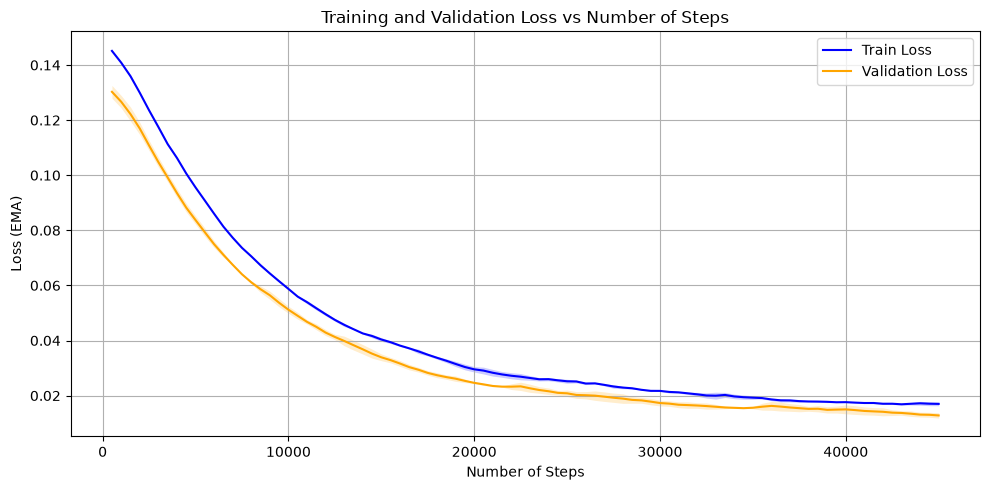

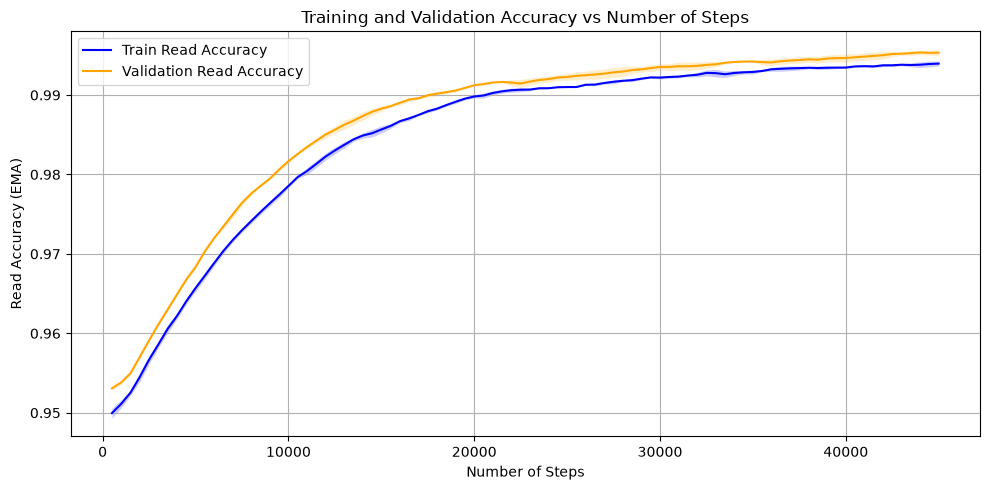

\begin{table}[!htb]
\centering
\caption{{\bf Different fine-tuning methods with and without using the best configuration of combined beam search modifications.}}
\resizebox{\linewidth}{!}{
\begin{tabular}{cccccccc}
\toprule
Fine-tune & Payload & Alignment & Read Acc & M Rate & X Rate & I Rate & D Rate \\
Method & Acc (\%) & Rate (\%) & (\%) & (\%) & (\%) & (\%) & (\%) \\
\midrule
\multirow{2}{*}{Whole-Model} & \cellcolor{blue!15}99.23 $\pm$ 0.01 & \cellcolor{blue!15}98.04 $\pm$ 0.01 & \cellcolor{blue!15}97.44 $\pm$ 0.00 & \cellcolor{blue!15}100.00 $\pm$ 0.00 & \cellcolor{blue!15}0.00 $\pm$ 0.00 & \cellcolor{blue!15}0.00 $\pm$ 0.00 & \cellcolor{blue!15}0.00 $\pm$ 0.00 \\
 & 99.26 $\pm$ 0.00 & 98.05 $\pm$ 0.00 & 97.44 $\pm$ 0.00 & 100.00 $\pm$ 0.00 & 0.00 $\pm$ 0.00 & 0.00 $\pm$ 0.00 & 0.00 $\pm$ 0.00 \\
\midrule
\multirow{2}{*}{Decoder} & \cellcolor{blue!15}42.39 $\pm$ 0.09 & \cellcolor{blue!15}63.18 $\pm$ 0.07 & \cellcolor{blue!15}90.60 $\pm$ 0.00 & \cellcolor{blue!15}95.35 $\pm$ 0.02 

In [9]:
# =====================================================================
# S2 / S3 / S4 supporting figures and table.
# Run after the notebook's import cell (cell 0) and helper cell (cell 1).
#
# Paths follow your scripts:
#   training logs (S3):  ../experiments/finetune_multiseed/seed_{1,2,42}/<model>/log.csv
#   S4 results:          ../experiments/s4_combined/train_{seed}/test_1/<model>[_combined]
#   data regime (S2):    ../experiments/finetune/<run>   (single runs, as before)
# =====================================================================
import os
from statistics import mean, stdev

import pandas as pd
import matplotlib.pyplot as plt

TRAIN_SEEDS = [1, 2, 42]
TRAIN_ROOT = os.path.join(PROJECT_ROOT, "..", "experiments", "finetune_multiseed")
OUT_PATH = os.path.join(PROJECT_ROOT, "..", "Reports", "Final Report", "images")
os.makedirs(OUT_PATH, exist_ok=True)


# %% ------------------------------------------------------------------
# S3 Fig: whole-model training curves, mean +/- SD over the 3 training seeds
# --------------------------------------------------------------------
WHOLE_MODEL = "5000_bacterial_benchmark_finetuned_45000"


def load_seed_logs(model, seeds=TRAIN_SEEDS):
    return [pd.read_csv(os.path.join(TRAIN_ROOT, f"seed_{s}", model, "log.csv")).set_index("num_steps")
            for s in seeds]


def plot_curve_across_seeds(frames, train_col, val_col, train_label, val_label, ylabel, title, out_file):
    plt.figure(figsize=(10, 5))
    for col, label, colour in [(train_col, train_label, "blue"), (val_col, val_label, "orange")]:
        # only steps logged by every seed
        stacked = pd.concat([f[col] for f in frames], axis=1, join="inner")
        m, s = stacked.mean(axis=1), stacked.std(axis=1, ddof=1)
        plt.plot(m.index, m, label=label, color=colour)
        plt.fill_between(m.index, m - s, m + s, color=colour, alpha=0.2, linewidth=0)
    plt.xlabel("Number of Steps")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(out_file, format="svg")
    plt.show()


whole_logs = load_seed_logs(WHOLE_MODEL)
plot_curve_across_seeds(whole_logs, "ema_train_loss", "ema_val_loss", "Train Loss", "Validation Loss",
                        "Loss (EMA)", "Training and Validation Loss vs Number of Steps",
                        os.path.join(OUT_PATH, "whole_model_finetune_loss.svg"))
plot_curve_across_seeds(whole_logs, "ema_train_acc", "ema_val_acc", "Train Read Accuracy", "Validation Read Accuracy",
                        "Read Accuracy (EMA)", "Training and Validation Accuracy vs Number of Steps",
                        os.path.join(OUT_PATH, "whole_model_finetune_acc.svg"))


# %% ------------------------------------------------------------------
# S2 Appendix: data regime plots (same runs and same figures as before)
# --------------------------------------------------------------------
number_of_reads = [1, 2, 3, 4, 5, 10, 25, 50, 100, 150, 192, 1914, 18930, 187165, 933902, 1866798]
regime_dirs = ["10000_images_model_finetune_rank_4_45000", "5000_images_model_finetune_rank_4_45000",
               "1000_images_model_finetune_rank_4_45000", "100_images_model_finetune_rank_4_45000",
               "10_images_model_finetune_rank_4_45000", "1_images_model_finetune_rank_4_45000",
               "lora_rank_4_150_reads_45000", "lora_rank_4_100_reads_45000", "lora_rank_4_50_reads_45000",
               "lora_rank_4_25_reads_45000", "lora_rank_4_10_reads_45000", "lora_rank_4_5_reads_45000",
               "lora_rank_4_4_reads_45000", "lora_rank_4_3_reads_45000", "lora_rank_4_2_reads_45000",
               "lora_rank_4_1_reads_45000"][::-1]
REGIME_ROOT = os.path.join(PROJECT_ROOT, "..", "experiments", "finetune")
regime_paths = [os.path.join(REGIME_ROOT, d) for d in regime_dirs]
missing_regime = [p for p in regime_paths if not os.path.isdir(p)]


# %% ------------------------------------------------------------------
# S4 Table: each fine-tuning method without (blue) and with the best combined
# beam search; mean +/- SD across the 3 training seeds on one test set
# --------------------------------------------------------------------
S4_ROOT = os.path.join(PROJECT_ROOT, "..", "experiments", "s4_combined")
S4_TEST_SEED = 1
SEQ_COUNTS = {"EBI": 37422, "MLK_excerpt_VBR_45-85": 34163, "View_huff3.cd": 3218,
              "watsoncrick": 56910, "wssnt10": 21649}
S4_MODELS = [("5000_bacterial_benchmark_finetuned_45000", "Whole-Model"),
             ("5000_images_model_decoder_finetune_45000", "Decoder")] + \
            [(f"5000_images_model_finetune_rank_{r}_45000", f"LoRA rank {r}") for r in (1, 2, 4, 8, 16)]
S4_COLUMNS = ["Payload Accuracy", "Alignment Success Rate", "Median Read Accuracy", "Median Match Rate",
              "Median Mismatch Rate", "Median Insertion Rate", "Median Deletion Rate"]


def weighted_mean(values, weights):
    vals = [(v, w) for v, w in zip(values, weights) if pd.notna(v)]
    return sum(v * w for v, w in vals) / sum(w for _, w in vals) if vals else float("nan")


def collect_s4_metrics(setting_path):
    """Per-file metrics merged across the 5 files by sequence count, as in Tables 1 and 4-9."""
    per_file = {c: [] for c in S4_COLUMNS}
    weights = []
    for g in SEQ_COUNTS:
        file_dir = os.path.join(setting_path, g)
        alignment_row = pd.read_csv(os.path.join(file_dir, "evaluation", "alignment_stats.csv")).iloc[0]
        basecall_stats_df = pd.read_csv(os.path.join(file_dir, "basecall_stats.csv"))
        failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
        alignment_rate = alignment_row["Aligned Reads"] / (
            alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)

        payload_accuracy = float("nan")
        payload_file = os.path.join(file_dir, "payload_accuracy.txt")
        if os.path.isfile(payload_file):
            with open(payload_file) as pf:
                try:
                    payload_accuracy = float(pf.read()) * 100
                except ValueError:
                    pass

        weights.append(SEQ_COUNTS[g])
        per_file["Payload Accuracy"].append(payload_accuracy)
        per_file["Alignment Success Rate"].append(alignment_rate * 100)
        if alignment_row["Aligned Reads"] != 0:
            eval_df = pd.read_csv(os.path.join(file_dir, "evaluation", "evaluation.csv"))
            per_file["Median Read Accuracy"].append(eval_df["Accuracy"].median() * 100)
            per_file["Median Match Rate"].append(eval_df["Match Rate"].median() * 100)
            per_file["Median Mismatch Rate"].append(eval_df["Mismatch Rate"].median() * 100)
            per_file["Median Insertion Rate"].append(eval_df["Insertion Rate"].median() * 100)
            per_file["Median Deletion Rate"].append(eval_df["Deletion Rate"].median() * 100)
        else:
            for c in S4_COLUMNS[2:]:
                per_file[c].append(float("nan"))
    return {c: weighted_mean(per_file[c], weights) for c in S4_COLUMNS}


def fmt_pm(xs, digits=2):
    xs = [x for x in xs if pd.notna(x)]
    if not xs:
        return "N/A"
    sd = stdev(xs) if len(xs) > 1 else 0.0
    return f"{mean(xs):.{digits}f} $\\pm$ {sd:.{digits}f}"


def s4_values(model, suffix):
    """{column: [value for each training seed]}"""
    out = {c: [] for c in S4_COLUMNS}
    for s in TRAIN_SEEDS:
        vals = collect_s4_metrics(os.path.join(S4_ROOT, f"train_{s}", f"test_{S4_TEST_SEED}", model + suffix))
        for c in S4_COLUMNS:
            out[c].append(vals[c])
    return out


body = []
gains = []
for i, (model, label) in enumerate(S4_MODELS):
    without, with_ = s4_values(model, ""), s4_values(model, "_combined")
    body.append(f"\\multirow{{2}}{{*}}{{{label}}} & "
                + " & ".join(f"\\cellcolor{{blue!15}}{fmt_pm(without[c])}" for c in S4_COLUMNS) + " \\\\")
    body.append(" & " + " & ".join(fmt_pm(with_[c]) for c in S4_COLUMNS) + " \\\\")
    if i < len(S4_MODELS) - 1:
        body.append("\\midrule")
    # paired gain (with - without) for each training seed, for checking the Results text
    gains.append((label, {c: [w - wo for w, wo in zip(with_[c], without[c])] for c in S4_COLUMNS[:3]}))

s4_latex = r"""\begin{table}[!htb]
\centering
\caption{{\bf Different fine-tuning methods with and without using the best configuration of combined beam search modifications.}}
\resizebox{\linewidth}{!}{
\begin{tabular}{cccccccc}
\toprule
Fine-tune & Payload & Alignment & Read Acc & M Rate & X Rate & I Rate & D Rate \\
Method & Acc (\%) & Rate (\%) & (\%) & (\%) & (\%) & (\%) & (\%) \\
\midrule
""" + "\n".join(body) + r"""
\bottomrule
\end{tabular}}
\begin{flushleft}The blue highlighted rows are the baseline without any modifications. Displays payload accuracy, alignment rate, median read accuracy and median match (M)/mismatch (X)/insertion (I)/deletion (D) rates. Values are mean $\pm$ SD across three independently fine-tuned models (training seeds 1, 2 and 42), each evaluated on the same simulated test set.
\end{flushleft}
\end{table}"""
print(s4_latex)

print("\nGain from the combined beam search (with - without), mean +/- SD over the 3 training seeds:")
for label, g in gains:
    parts = [c.replace("Median ", "") + ": " + fmt_pm(v).replace(" $\\pm$ ", " ± ") for c, v in g.items()]
    print(f"  {label:<13} " + "   ".join(parts))